In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score

import joblib
from google.colab import files

In [2]:
uploaded = files.upload()

Saving Logistic_Regression_Model.pkl to Logistic_Regression_Model.pkl
Saving NLP_Preprocessed_Dataset.xlsx to NLP_Preprocessed_Dataset.xlsx


In [3]:
df = pd.read_excel("NLP_Preprocessed_Dataset.xlsx")

TEXT_COLUMN = "nlp_text"
LABEL_COLUMN = "label"

df = df[[TEXT_COLUMN, LABEL_COLUMN]].dropna().copy()

df[TEXT_COLUMN] = df[TEXT_COLUMN].astype(str)
df[LABEL_COLUMN] = df[LABEL_COLUMN].astype(str).str.strip().str.upper()

print("Dataset shape:", df.shape)
print(df[LABEL_COLUMN].value_counts())

Dataset shape: (3200, 2)
label
INFORMATION       1600
MISINFORMATION    1600
Name: count, dtype: int64


In [4]:
X = df[TEXT_COLUMN]
y = df[LABEL_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Test samples:", len(X_test))

Test samples: 640


In [5]:
uploaded = files.upload()

Saving TFIDF_Vectorizer.pkl to TFIDF_Vectorizer.pkl


In [6]:
tfidf_vectorizer = joblib.load("TFIDF_Vectorizer.pkl")

X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("TF-IDF test matrix:", X_test_tfidf.shape)

TF-IDF test matrix: (640, 632)


In [8]:
MODEL_FILE = "Logistic_Regression_Model.pkl"

best_model = joblib.load(MODEL_FILE)

print("Loaded model:", MODEL_FILE)

Loaded model: Logistic_Regression_Model.pkl


In [9]:
y_pred = best_model.predict(X_test_tfidf)

print("Predictions generated successfully")

print("Actual labels:")
print(y_test.head())

print("Predicted labels:")
print(y_pred[:5])

Predictions generated successfully
Actual labels:
1858       INFORMATION
2024       INFORMATION
3075    MISINFORMATION
2120       INFORMATION
2165    MISINFORMATION
Name: label, dtype: object
Predicted labels:
['INFORMATION' 'INFORMATION' 'MISINFORMATION' 'INFORMATION'
 'MISINFORMATION']


In [10]:
error_df = pd.DataFrame({
    "Text": X_test.values,
    "Actual_Label": y_test.values,
    "Predicted_Label": y_pred
})

error_df["Correct_Prediction"] = (
    error_df["Actual_Label"] == error_df["Predicted_Label"]
)

error_df["Error_Type"] = np.where(
    error_df["Correct_Prediction"],
    "Correct",
    np.where(
        (error_df["Actual_Label"] == "INFORMATION") &
        (error_df["Predicted_Label"] == "MISINFORMATION"),
        "False Positive",
        "False Negative"
    )
)

error_df.head()

,Text,Actual_Label,Predicted_Label,Correct_Prediction,Error_Type
0,గమనిక పంటను విక్రయించే ముందు మార్కెట్ ధరలను పర...,INFORMATION,INFORMATION,True,Correct
1,వ్యవసాయ సమాచారం సేంద్రీయ పదార్థాలను ఉపయోగించేట...,INFORMATION,INFORMATION,True,Correct
2,గమనిక ఈ లింక్ పై క్లిక్ చేస్తే పథకం డబ్బు వెంట...,MISINFORMATION,MISINFORMATION,True,Correct
3,వ్యవసాయ సమాచారం వర్షపాతం మరియు ఉష్ణోగ్రత పంట ఎ...,INFORMATION,INFORMATION,True,Correct
4,గమనిక ఈ లింక్ పై క్లిక్ చేస్తే పథకం డబ్బు వెంట...,MISINFORMATION,MISINFORMATION,True,Correct


In [11]:
errors = error_df[
    error_df["Correct_Prediction"] == False
]

print("Total test samples:", len(error_df))
print("Incorrect predictions:", len(errors))

errors.head(10)

Total test samples: 640
Incorrect predictions: 0


,Text,Actual_Label,Predicted_Label,Correct_Prediction,Error_Type


In [12]:
false_positives = error_df[
    error_df["Error_Type"] == "False Positive"
]

print("False Positives:", len(false_positives))

false_positives.head(10)

False Positives: 0


,Text,Actual_Label,Predicted_Label,Correct_Prediction,Error_Type


In [13]:
false_positives.to_csv(
    "False_Positive_Samples.csv",
    index=False
)

In [14]:
false_negatives = error_df[
    error_df["Error_Type"] == "False Negative"
]

print("False Negatives:", len(false_negatives))

false_negatives.head(10)

False Negatives: 0


,Text,Actual_Label,Predicted_Label,Correct_Prediction,Error_Type


In [15]:
false_negatives.to_csv(
    "False_Negative_Samples.csv",
    index=False
)

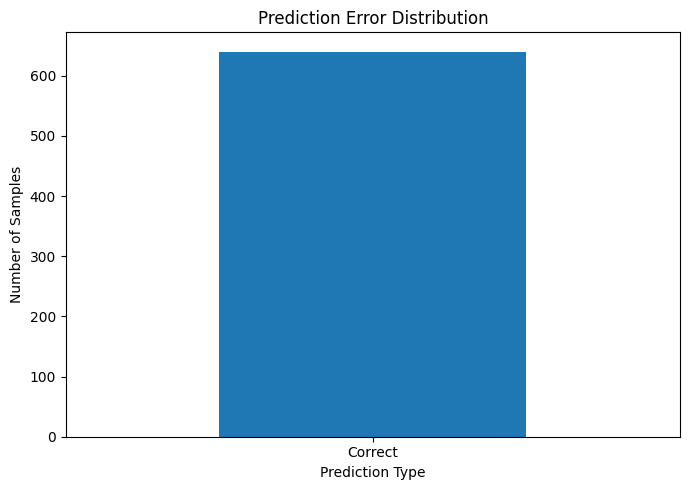

In [16]:
error_counts = error_df["Error_Type"].value_counts()

plt.figure(figsize=(7, 5))

error_counts.plot(kind="bar")

plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("Error_Distribution.png", dpi=300)
plt.show()

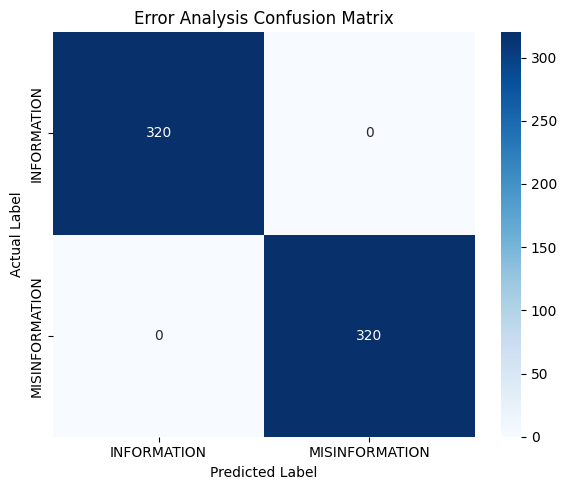

In [17]:
labels = ["INFORMATION", "MISINFORMATION"]

cm = confusion_matrix(
    error_df["Actual_Label"],
    error_df["Predicted_Label"],
    labels=labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Error Analysis Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.savefig("Error_Analysis_Confusion_Matrix.png", dpi=300)
plt.show()

In [18]:
total = len(error_df)
correct = error_df["Correct_Prediction"].sum()
incorrect = total - correct

summary = pd.DataFrame({
    "Metric": [
        "Total Test Samples",
        "Correct Predictions",
        "Incorrect Predictions",
        "False Positives",
        "False Negatives",
        "Accuracy"
    ],
    "Value": [
        total,
        correct,
        incorrect,
        len(false_positives),
        len(false_negatives),
        accuracy_score(
            error_df["Actual_Label"],
            error_df["Predicted_Label"]
        )
    ]
})

summary

,Metric,Value
0,Total Test Samples,640.0
1,Correct Predictions,640.0
2,Incorrect Predictions,0.0
3,False Positives,0.0
4,False Negatives,0.0
5,Accuracy,1.0


In [19]:
summary.to_csv(
    "Error_Analysis_Summary.csv",
    index=False
)

In [20]:
print("FALSE POSITIVE EXAMPLES")
display(false_positives[["Text", "Actual_Label", "Predicted_Label"]].head(5))

print("\nFALSE NEGATIVE EXAMPLES")
display(false_negatives[["Text", "Actual_Label", "Predicted_Label"]].head(5))

FALSE POSITIVE EXAMPLES


,Text,Actual_Label,Predicted_Label



FALSE NEGATIVE EXAMPLES


,Text,Actual_Label,Predicted_Label


In [21]:
error_df.to_csv(
    "Error_Analysis_Dataset.csv",
    index=False
)

print("Error analysis dataset saved")

Error analysis dataset saved


In [22]:
from google.colab import files

files.download("Error_Analysis_Dataset.csv")
files.download("False_Positive_Samples.csv")
files.download("False_Negative_Samples.csv")
files.download("Error_Analysis_Summary.csv")
files.download("Error_Distribution.png")
files.download("Error_Analysis_Confusion_Matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>